# Lab 2: Навчання без учителя та обробка текстових даних

## Мета роботи
Ознайомитися з базовими методами навчання без учителя та обробки текстів: зниженням розмірності (PCA, t-SNE), візуалізацією та кластеризацією (K-Means), а також побудовою базового workflow класифікації текстів у Scikit-learn.

## Дані
- **Завдання 1-2:** датасет з Lab 1 - Phishing URL / Websites dataset (`final_dataset.csv`, Kaggle), ціль `label`: `0` - легітимний сайт, `1` - фішинговий. Попередня обробка така сама, як у Lab 1 (вилучено сирий `url` та стовпці-дублікати).
- **Завдання 3:** текстовий датасет **SMS Spam Collection** (UCI / Kaggle) - 2 класи: `ham` (звичайне повідомлення) і `spam`. Обрано, бо він тематично близький до Lab 1 (шахрайські повідомлення), має лише 2 класи, невеликий за розміром і не є IMDB.

## Завдання
1. Зниження розмірності та візуалізація: PCA (порівняння класифікації "до" і "після"), t-SNE у 2D
2. Кластерний аналіз: K-Means, Elbow / Silhouette, візуалізація, порівняння кластерів із класами
3. Обробка та класифікація текстів: передобробка, WordCloud, TF-IDF, класифікація, метрики

In [ ]:
import os
import re
import io
import sys
import time
import zipfile
import warnings
import subprocess
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 100

print("Setup!")

Setup!


## Завантаження та підготовка даних Lab 1
Завантажуємо той самий файл `final_dataset.csv` і повторюємо рішення з попередньої обробки Lab 1: вилучаємо сирий `url` (≈580 тис. унікальних значень) та п'ять пар ознак-дублікатів. Пропущених значень у датасеті немає.

In [ ]:
CSV_NAME = "final_dataset.csv"
candidates = [CSV_NAME, os.path.join("data", CSV_NAME)]
csv_path = next((p for p in candidates if os.path.exists(p)), None)

if csv_path is None:
    import kagglehub
    path = kagglehub.dataset_download("elifzelik/phishing-url-features-dataset")
    print(f"Path to dataset files: {path}")
    csv_path = os.path.join(path, CSV_NAME)

print(f"Using file: {csv_path}")
df = pd.read_csv(csv_path)
target = "label"

non_numeric = df.drop(columns=[target]).select_dtypes(exclude="number").columns.tolist()
df = df.drop(columns=non_numeric)
print("Dropped non-numeric columns:", non_numeric)

if df.isnull().sum().sum() > 0:
    df = df.fillna(df.median(numeric_only=True))

feature_cols = [c for c in df.columns if c != target]
hashes = {c: int(pd.util.hash_pandas_object(df[c], index=False).sum()) for c in feature_cols}
by_hash = {}
for c, h in hashes.items():
    by_hash.setdefault(h, []).append(c)
duplicate_columns = []
for group in by_hash.values():
    first = group[0]
    for other in group[1:]:
        if df[first].equals(df[other]):
            duplicate_columns.append(other)
            print(f"Duplicate feature: '{other}' is identical to '{first}'")
df = df.drop(columns=duplicate_columns)

X = df.drop(columns=[target])
y = df[target]
print(f"\nObjects: {X.shape[0]}, features: {X.shape[1]}")
print("Class distribution:\n", y.value_counts(normalize=True).sort_index().round(4))

Using file: C:\Users\oleks\.cache\kagglehub\datasets\elifzelik\phishing-url-features-dataset\versions\2\final_dataset.csv
Dropped non-numeric columns: ['url']
Duplicate feature: 'tld_length_domain' is identical to 'tld_length'
Duplicate feature: 'path_segments_count' is identical to 'url_depth'
Duplicate feature: 'num_special' is identical to 'num_special_chars'
Duplicate feature: 'query_key_count' is identical to 'num_params'
Duplicate feature: 'starts_with_ip' is identical to 'is_ip_address'

Objects: 579920, features: 69
Class distribution:
 label
0    0.5847
1    0.4153
Name: proportion, dtype: float64


## 1) Зниження розмірності та візуалізація даних

### 1.1 Підготовка: розбиття та масштабування
PCA чутливий до масштабу ознак (він шукає напрями максимальної дисперсії, тож ознака з великими числами, наприклад `domain_age_days`, «перетягнула б» компоненти). Тому спочатку `StandardScaler`.

Щоб не було витоку інформації, **і scaler, і PCA навчаються лише на training-частині**, а test тільки перетворюється.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype(np.float32)
X_test_s = scaler.transform(X_test).astype(np.float32)

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (463936, 69) | Test: (115984, 69)


### 1.2 PCA: скільки компонент потрібно?
Навчаємо PCA з усіма компонентами та дивимося на частку поясненої дисперсії (scree plot і кумулятивна крива).

90% variance -> 38 components (of 69)
95% variance -> 44 components (of 69)
99% variance -> 54 components (of 69)


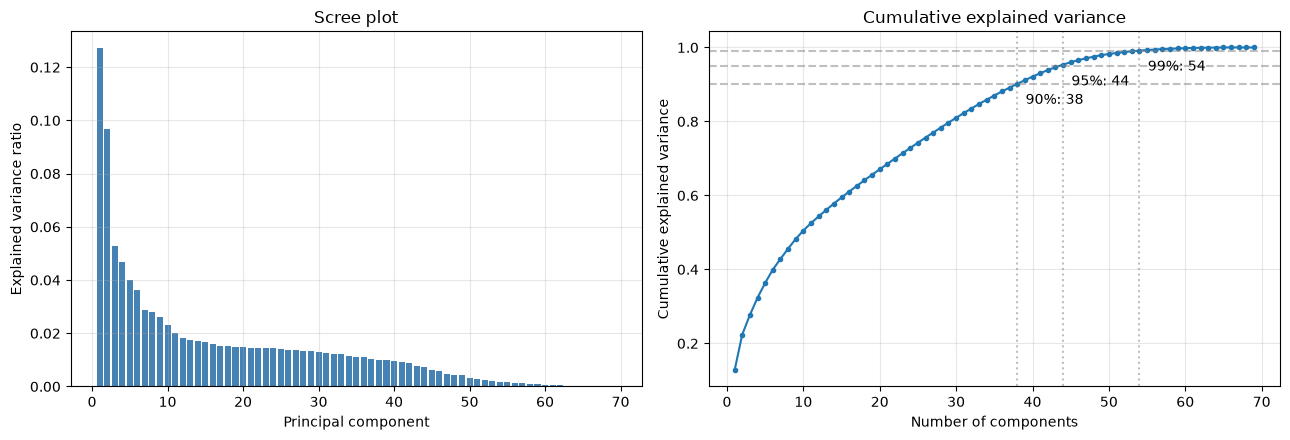

In [5]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

n_components_for = {thr: int(np.searchsorted(cum, thr) + 1) for thr in (0.90, 0.95, 0.99)}
for thr, n in n_components_for.items():
    print(f"{thr:.0%} variance -> {n} components (of {X_train_s.shape[1]})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(evr) + 1), evr, color="steelblue")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Scree plot")
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, len(cum) + 1), cum, marker="o", ms=3)
for thr, n in n_components_for.items():
    axes[1].axhline(thr, color="gray", ls="--", alpha=0.5)
    axes[1].axvline(n, color="gray", ls=":", alpha=0.5)
    axes[1].annotate(f"{thr:.0%}: {n}", (n, thr), textcoords="offset points", xytext=(6, -14))
axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Cumulative explained variance")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Що показують головні компоненти.** Кожна компонента - це лінійна комбінація вихідних ознак. Подивимося, які ознаки мають найбільші за модулем ваги (loadings) у перших трьох компонентах.

In [6]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(6).index
    print(f"{pc} (explains {evr[int(pc[2:]) - 1]:.1%}):")
    print(loadings.loc[top, pc].round(3).to_string(), "\n")

PC1 (explains 12.7%):
query_entropy    0.254
num_params       0.252
num_equals       0.251
num_digits       0.245
query_length     0.241
num_question     0.241 

PC2 (explains 9.7%):
dns_resolves       0.280
has_ns_record      0.279
has_mx_record      0.275
domain_age_days    0.273
creation_year      0.249
has_txt_record     0.225 

PC3 (explains 5.3%):
success             0.326
is_ip_address      -0.326
whois_missing      -0.326
entropy_hostname    0.308
hostname_length     0.225
ratio_letters       0.192 



### 1.3 Класифікація «до» і «після» PCA
Для порівняння беремо **Random Forest** - найкращу модель із Lab 1. Порівнюємо:

- **Original** - усі масштабовані ознаки;
- **PCA 90 % / 95 % / 99 %** - стільки компонент, щоб зберегти відповідну частку дисперсії.

Для кожного варіанта фіксуємо метрики на test, час навчання PCA, час навчання моделі та час прогнозу. Усі моделі оцінюємо на одному й тому ж test-наборі.

In [7]:
def make_rf():
    return RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

def evaluate_variant(name, model_fn, Xtr, ytr, Xte, yte, n_features, pca_time=0.0):
    model = model_fn()
    t0 = time.time(); model.fit(Xtr, ytr); fit_time = time.time() - t0
    t0 = time.time()
    score = model.predict_proba(Xte)[:, 1]
    predict_time = time.time() - t0
    y_pred = (score > 0.5).astype(int)
    return {
        "Variant": name, "Features": n_features,
        "Accuracy": accuracy_score(yte, y_pred), "Precision": precision_score(yte, y_pred),
        "Recall": recall_score(yte, y_pred), "F1": f1_score(yte, y_pred),
        "ROC-AUC": roc_auc_score(yte, score),
        "PCA, s": pca_time, "Fit, s": fit_time, "Total train, s": pca_time + fit_time,
        "Predict, s": predict_time,
    }

def run_pca_experiment(model_fn, Xtr, ytr, Xte, yte, label=""):
    rows = [evaluate_variant("Original", model_fn, Xtr, ytr, Xte, yte, Xtr.shape[1])]
    print(rows[-1]["Variant"], "done")
    for thr in (0.90, 0.95, 0.99):
        t0 = time.time()
        pca = PCA(n_components=thr, svd_solver="full", random_state=RANDOM_STATE).fit(Xtr)
        Xtr_p, Xte_p = pca.transform(Xtr), pca.transform(Xte)
        pca_time = time.time() - t0
        rows.append(evaluate_variant(f"PCA {thr:.0%}", model_fn, Xtr_p, ytr, Xte_p, yte,
                                     pca.n_components_, pca_time))
        print(rows[-1]["Variant"], "done")
    return pd.DataFrame(rows).set_index("Variant")

rf_results = run_pca_experiment(make_rf, X_train_s, y_train, X_test_s, y_test)
rf_results["Reduction"] = (X_train_s.shape[1] / rf_results["Features"]).round(2)
pd.options.display.float_format = "{:.4f}".format
rf_results

Original done
PCA 90% done
PCA 95% done
PCA 99% done


,Features,Accuracy,Precision,Recall,F1,ROC-AUC,"PCA, s","Fit, s","Total train, s","Predict, s",Reduction
Variant,,,,,,,,,,,
Original,69,0.9850,0.9906,0.9730,0.9817,0.9981,0.0000,49.5812,49.5812,0.7481,1.0000
PCA 90%,38,0.9769,0.9804,0.9635,0.9719,0.9963,2.0750,140.6799,142.7549,0.5448,1.8200
PCA 95%,44,0.9773,0.9815,0.9636,0.9724,0.9964,2.2230,147.2916,149.5146,0.5901,1.5700
PCA 99%,54,0.9781,0.9822,0.9647,0.9734,0.9966,2.3590,180.2024,182.5614,0.8875,1.2800


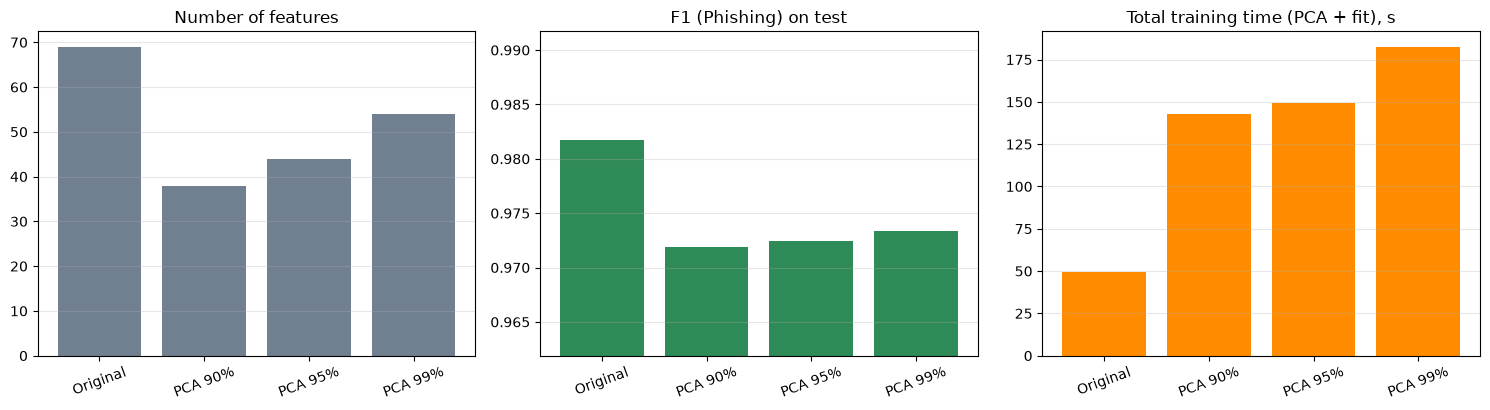

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
names = rf_results.index.tolist()
axes[0].bar(names, rf_results["Features"], color="slategray")
axes[0].set_title("Number of features")
axes[1].bar(names, rf_results["F1"], color="seagreen")
axes[1].set_ylim(rf_results["F1"].min() - 0.01, min(1.0, rf_results["F1"].max() + 0.01))
axes[1].set_title("F1 (Phishing) on test")
axes[2].bar(names, rf_results["Total train, s"], color="darkorange")
axes[2].set_title("Total training time (PCA + fit), s")
for ax in axes:
    ax.grid(alpha=0.3, axis="y"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Додатково: kNN.** Random Forest - дерева, вони майже не залежать від кореляцій між ознаками. kNN працює з відстанями, тому на ньому ефект PCA може бути іншим. Щоб експеримент не тривав годинами, kNN навчаємо на підвибірці training (50 000) і оцінюємо на підвибірці test (20 000), однаковій для всіх варіантів.

In [9]:
RUN_KNN = True
KNN_TRAIN, KNN_TEST = 50_000, 20_000

if RUN_KNN:
    Xk_tr, _, yk_tr, _ = train_test_split(X_train_s, y_train, train_size=KNN_TRAIN,
                                          stratify=y_train, random_state=RANDOM_STATE)
    Xk_te, _, yk_te, _ = train_test_split(X_test_s, y_test, train_size=KNN_TEST,
                                          stratify=y_test, random_state=RANDOM_STATE)
    knn_results = run_pca_experiment(lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
                                     Xk_tr, yk_tr, Xk_te, yk_te)
    display(knn_results[["Features", "Accuracy", "F1", "ROC-AUC", "PCA, s", "Fit, s", "Predict, s"]])

Original done
PCA 90% done
PCA 95% done
PCA 99% done


,Features,Accuracy,F1,ROC-AUC,"PCA, s","Fit, s","Predict, s"
Variant,,,,,,,
Original,69,0.9570,0.9475,0.9820,0.0000,0.0040,2.4671
PCA 90%,38,0.9571,0.9477,0.9826,0.3990,0.0050,1.7930
PCA 95%,44,0.9567,0.9472,0.9823,0.1290,0.0050,1.6440
PCA 99%,53,0.9573,0.9479,0.9821,0.1350,0.0050,1.7501


In [10]:
# Автоматичний підсумок за отриманими числами (Random Forest)
base, p95 = rf_results.loc["Original"], rf_results.loc["PCA 95%"]
d_acc = (p95["Accuracy"] - base["Accuracy"]) * 100
d_f1 = (p95["F1"] - base["F1"]) * 100

print("ПІДСУМОК PCA (Random Forest)")
print(f"- Ознак: {int(base['Features'])} -> {int(p95['Features'])} при 95% дисперсії "
      f"(у {base['Features'] / p95['Features']:.2f} раза менше, -{(1 - p95['Features'] / base['Features']):.0%}).")
print(f"- Accuracy: {base['Accuracy']:.4f} -> {p95['Accuracy']:.4f} ({d_acc:+.2f} в.п.); "
      f"F1: {base['F1']:.4f} -> {p95['F1']:.4f} ({d_f1:+.2f} в.п.).")
print(f"- Час навчання моделі: {base['Fit, s']:.1f} c -> {p95['Fit, s']:.1f} c; "
      f"разом з PCA: {p95['Total train, s']:.1f} c; прогноз: {base['Predict, s']:.2f} c -> {p95['Predict, s']:.2f} c.")
verdict = ("якість практично не змінилась" if abs(d_acc) < 0.3 else
           "якість погіршилась" if d_acc < 0 else "якість покращилась")
print(f"- Висновок: {verdict}.")

ПІДСУМОК PCA (Random Forest)
- Ознак: 69 -> 44 при 95% дисперсії (у 1.57 раза менше, -36%).
- Accuracy: 0.9850 -> 0.9773 (-0.76 в.п.); F1: 0.9817 -> 0.9724 (-0.93 в.п.).
- Час навчання моделі: 49.6 c -> 147.3 c; разом з PCA: 149.5 c; прогноз: 0.75 c -> 0.59 c.
- Висновок: якість погіршилась.


### Висновки щодо PCA
- **Як PCA вплинув на якість.** Порівняйте Accuracy / F1 / ROC-AUC у рядках `Original` та `PCA 95 %`. Якщо різниця в межах десятих часток відсотка - PCA зберіг майже всю корисну інформацію. Падіння якості пояснюється тим, що PCA зберігає **дисперсію**, а не **інформативність для класів**: ознака з малою дисперсією (наприклад, бінарна `has_mx_record`) може сильно розділяти класи, але мало впливати на головні компоненти.
- **Скільки ознак вдалося прибрати.** Кількість компонент для 90 / 95 / 99 % дисперсії - у scree plot і таблиці. Багато ознак датасету сильно корельовані (див. EDA в Lab 1), тому їх можна стиснути в меншу кількість компонент.
- **Час.** Менше ознак не означає швидшого лісу: компоненти PCA - щільні неперервні числа з величезною кількістю унікальних порогів, а вихідні ознаки частково бінарні/дискретні, для яких пошук розбиття дешевий. Тому час навчання Random Forest після PCA може навіть зрости (див. таблицю), і до нього додається час самого PCA. Для kNN відстань рахується по меншій кількості координат, тож там виграш ймовірніший.
- **Ціна.** Після PCA ознаки втрачають зміст («компонента 7» важко пояснити), тобто падає інтерпретовність моделі. Для дерев/лісу, які стійкі до кореляцій, PCA зазвичай не потрібен для якості.

### 1.4 t-SNE: візуалізація в 2D
t-SNE - нелінійний метод, який зберігає **локальні сусідства**: близькі точки у вихідному просторі лишаються близькими на площині. Він повільний (приблизно O(n log n), але з великою константою), тому береться **стратифікована підвибірка 10 000 об'єктів**. Перед t-SNE дані стискаємо PCA до 50 компонент (стандартна практика: прискорює і прибирає шум). Колір - справжній клас; мітки t-SNE при навчанні **не використовуються**.

Для порівняння поруч показано проєкцію на перші дві компоненти PCA для тих самих точок.

t-SNE time on 10000 points: 29.2 s, KL divergence = 1.199


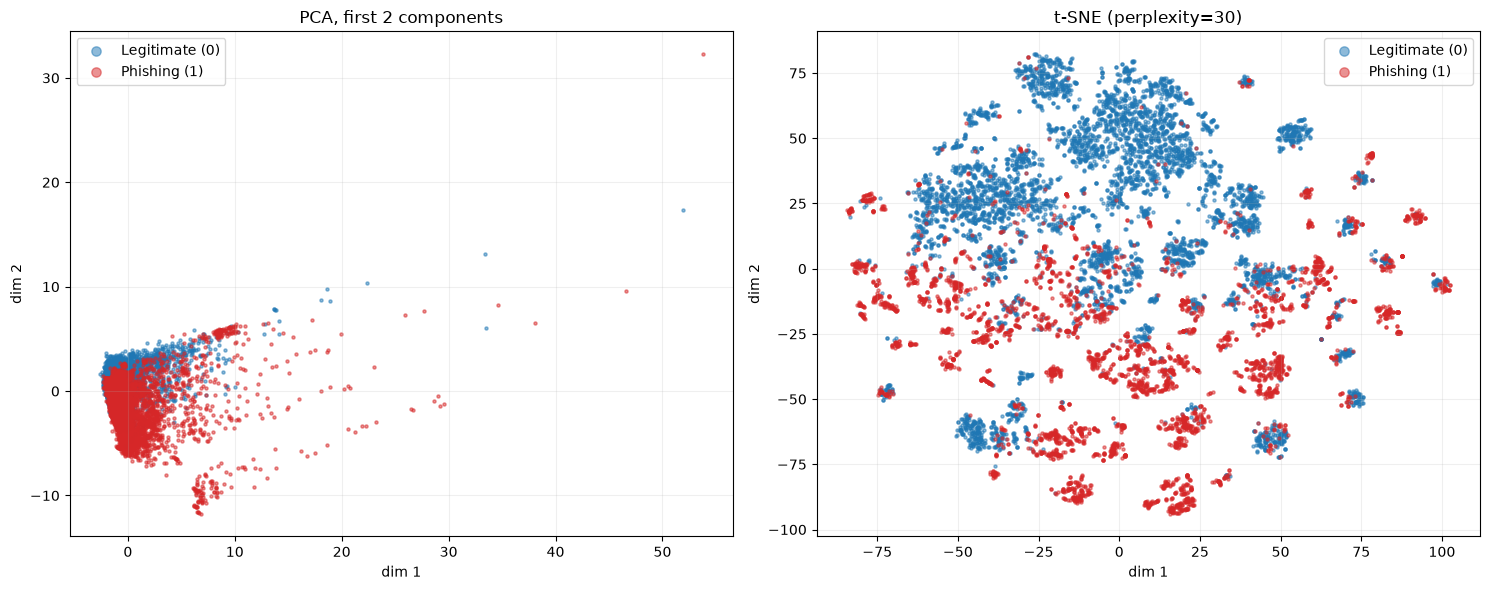

In [11]:
TSNE_SIZE = 10_000
X_vis, _, y_vis, _ = train_test_split(X_train_s, y_train.values, train_size=TSNE_SIZE,
                                      stratify=y_train.values, random_state=RANDOM_STATE)

n_pre = min(50, X_vis.shape[1])
X_vis_pre = PCA(n_components=n_pre, random_state=RANDOM_STATE).fit_transform(X_vis)

t0 = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            random_state=RANDOM_STATE, n_jobs=-1)
X_tsne = tsne.fit_transform(X_vis_pre)
print(f"t-SNE time on {TSNE_SIZE} points: {time.time() - t0:.1f} s, KL divergence = {tsne.kl_divergence_:.3f}")

X_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_vis)

def scatter_classes(ax, emb, labels, title, s=5):
    for cls, name, color in [(0, "Legitimate (0)", "tab:blue"), (1, "Phishing (1)", "tab:red")]:
        m = labels == cls
        ax.scatter(emb[m, 0], emb[m, 1], s=s, alpha=0.5, c=color, label=name)
    ax.set_title(title); ax.set_xlabel("dim 1"); ax.set_ylabel("dim 2")
    ax.legend(markerscale=3); ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
scatter_classes(axes[0], X_pca2, y_vis, "PCA, first 2 components")
scatter_classes(axes[1], X_tsne, y_vis, "t-SNE (perplexity=30)")
plt.tight_layout(); plt.show()

**Вплив perplexity.** Perplexity - приблизна «кількість сусідів», яку t-SNE враховує для кожної точки. Мала величина підкреслює дрібні локальні групи, велика - глобальнішу структуру. Порівняємо три значення на 5 000 точок.

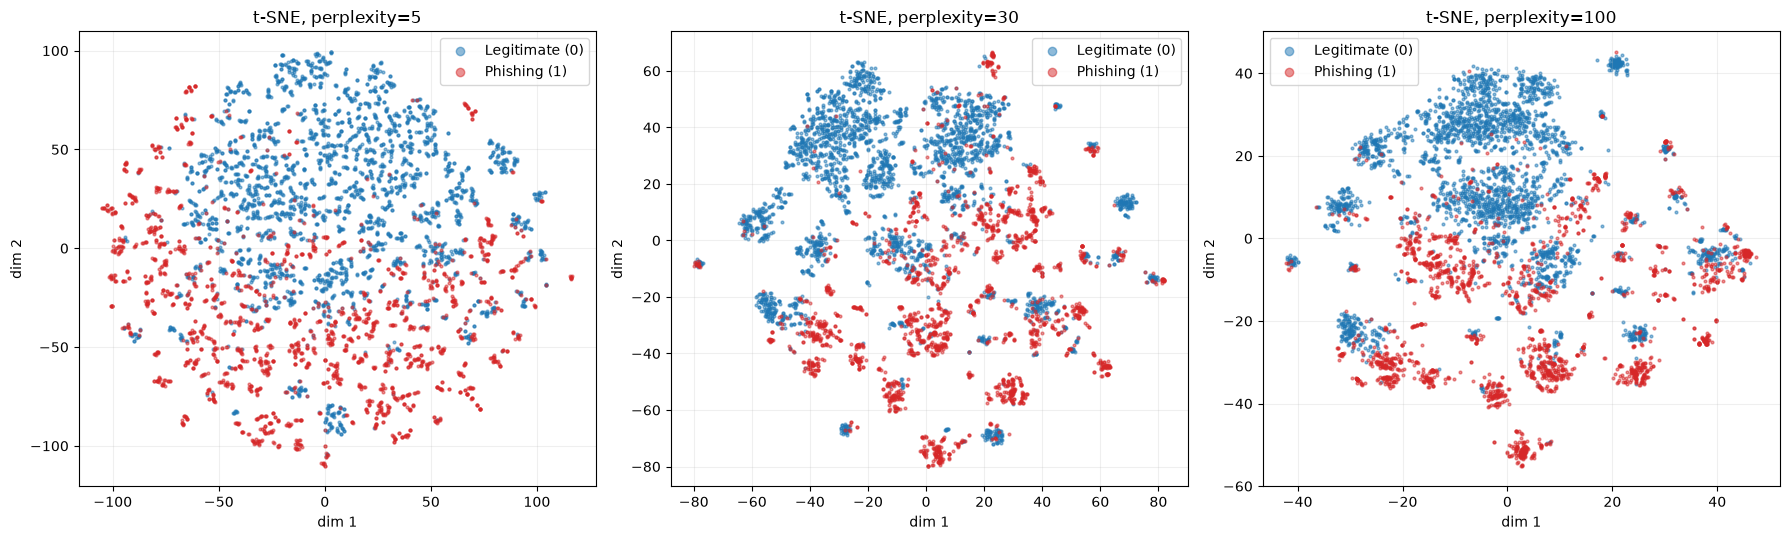

In [12]:
sub = 5_000
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, perp in zip(axes, (5, 30, 100)):
    emb = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto",
               random_state=RANDOM_STATE, n_jobs=-1).fit_transform(X_vis_pre[:sub])
    scatter_classes(ax, emb, y_vis[:sub], f"t-SNE, perplexity={perp}", s=4)
plt.tight_layout(); plt.show()

In [13]:
# Кількісна перевірка «на око»: наскільки добре класи розділяються у 2D-вкладенні?
# 5-NN з 5-fold CV на 2D-координатах (вкладення навчене на всіх точках, тому це лише описова оцінка).
knn2 = KNeighborsClassifier(n_neighbors=5)
acc_pca2 = cross_val_score(knn2, X_pca2, y_vis, cv=5).mean()
acc_tsne = cross_val_score(knn2, X_tsne, y_vis, cv=5).mean()
print(f"5-NN accuracy in 2D  PCA : {acc_pca2:.4f}")
print(f"5-NN accuracy in 2D  t-SNE: {acc_tsne:.4f}")
print(f"Majority-class baseline : {max(y_vis.mean(), 1 - y_vis.mean()):.4f}")

5-NN accuracy in 2D  PCA : 0.8009
5-NN accuracy in 2D  t-SNE: 0.9359
Majority-class baseline : 0.5847


### Висновки щодо t-SNE
- **Острівці одного кольору** означають, що об'єкти цього класу мають схожі вектори ознак, тобто класи розділяються за ознаками (тому Random Forest у Lab 1 працював добре). Точки різних кольорів, що перемішані на межі або в окремих «островах», - це URL, ознаки яких схожі на ознаки іншого класу; саме там модель помилятиметься.
- **PCA vs t-SNE.** PCA - лінійна проєкція на 2 напрями найбільшої дисперсії, тому на площині лишається лише частина інформації (див. частку дисперсії двох перших компонент) і класи сильніше накладаються. t-SNE нелінійний і зберігає локальні сусідства, тому групи видно чіткіше. Число 5-NN accuracy вище показує це кількісно.
- **Обмеження t-SNE.** Відстані між «островами» та їхні розміри **не мають прямого змісту**; результат залежить від perplexity та random_state; метод не має `transform()` для нових точок, тому використовується лише для візуалізації, а не як крок перед моделлю.
- Характер «островів» (кілька окремих груп одного класу) вказує, що клас неоднорідний: наприклад, фішингові URL із відсутніми WHOIS-даними та фішингові URL зі звичайним доменом - це різні підтипи.

## 2) Кластерний аналіз (K-Means)

Кластеризація - навчання **без учителя**: мітки `label` під час кластеризації не використовуються. Їх ми беремо лише **після** того, як кластери побудовано, щоб оцінити, чи збігається знайдена структура з реальними класами.

Датасет має лише 2 класи, тому відбирати класи не потрібно. Для швидкості беремо **випадкову** (не стратифіковану за міткою, щоб не використовувати `label`) підвибірку 50 000 об'єктів з масштабованих даних. Масштабування обов'язкове: K-Means працює з евклідовою відстанню. Також потрібна стійкість до викидів.

In [ ]:
CLUSTER_N = 50_000
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_train_s), size=CLUSTER_N, replace=False)

# K-Means дуже чутливий до викидів: у цьому датасеті є URL довжиною у десятки тисяч символів, і після
# StandardScaler один такий об'єкт має z-оцінку у сотні одиниць та захоплює окремий кластер (перша спроба дала кластер із 1 об'єкта). 
# Тому для кластеризації стискаємо важкі хвости: log1p для невід'ємних
# неперервних ознак (не 0/1), потім масштабування.
cont_cols = [c for c in X.columns if X[c].nunique() > 2 and X[c].min() >= 0]
X_cl = X_train.copy()
X_cl[cont_cols] = np.log1p(X_cl[cont_cols])
X_cl_s = StandardScaler().fit_transform(X_cl).astype(np.float32)
print(f"log1p applied to {len(cont_cols)} of {X.shape[1]} features; max |z| before: "
      f"{np.abs(X_train_s).max():.0f}, after: {np.abs(X_cl_s).max():.1f}")

Xc = X_cl_s[idx]                       # ознаки для кластеризації
y_true = y_train.values[idx]           # справжні класи - ТІЛЬКИ для порівняння після кластеризації
Xc_raw = X_train.iloc[idx]             # ознаки у вихідних одиницях - для інтерпретації кластерів
print("Clustering sample:", Xc.shape, "| phishing share (not used for clustering):", y_true.mean().round(4))

log1p applied to 38 of 69 features; max |z| before: 366, after: 59.6
Clustering sample: (50000, 69) | phishing share (not used for clustering): 0.4166


### 2.1 Вибір кількості кластерів: Elbow та Silhouette
- **Elbow:** inertia (сума квадратів відстаней до центроїда) завжди спадає зі зростанням k; шукаємо місце, після якого спад різко сповільнюється.
- **Silhouette:** для кожної точки порівнює середню відстань до свого кластера з відстанню до найближчого чужого; значення від −1 до 1, чим більше, тим краще.
- **Davies-Bouldin** (додатково): чим менше, тим краще.

Silhouette має складність O(n²), тому рахується на підвибірці 10 000 точок.

k= 2  inertia=     2993602  silhouette=0.4192  DB=1.536
k= 3  inertia=     2711968  silhouette=0.2183  DB=2.061
k= 4  inertia=     2529154  silhouette=0.2058  DB=1.766
k= 5  inertia=     2410451  silhouette=0.1635  DB=1.850
k= 6  inertia=     2325066  silhouette=0.1623  DB=2.061
k= 7  inertia=     2253602  silhouette=0.1085  DB=2.122
k= 8  inertia=     2210229  silhouette=0.1065  DB=2.182
k= 9  inertia=     2161552  silhouette=0.0992  DB=2.191
k=10  inertia=     2101079  silhouette=0.1089  DB=2.156

Elbow (geometric) suggests k = 5;  best silhouette at k = 2


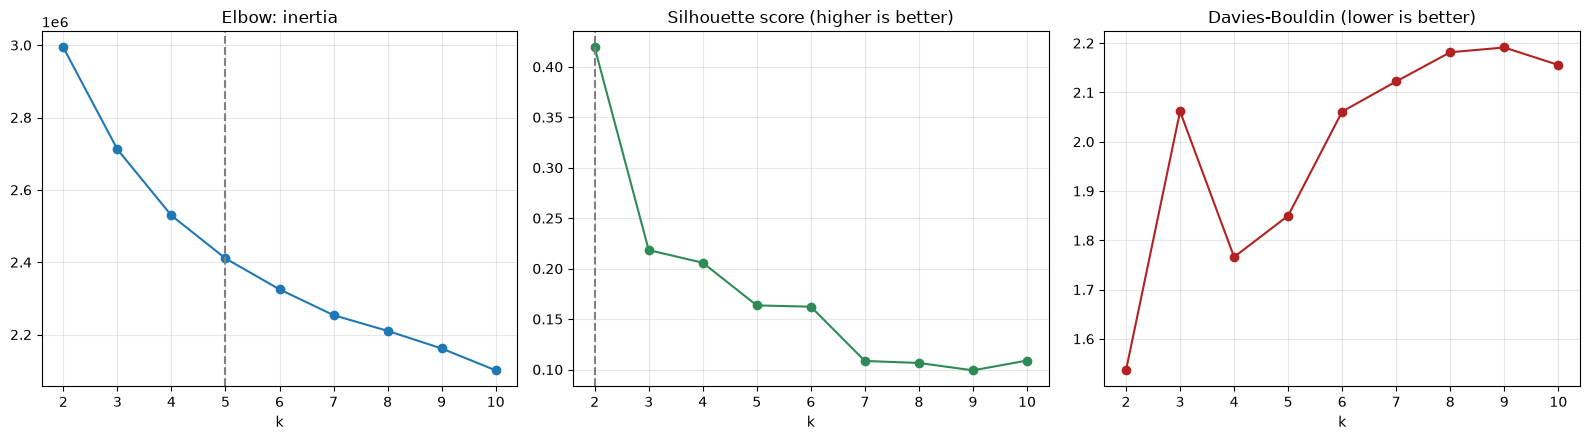

In [ ]:
K_RANGE = range(2, 11)
inertias, sils, dbs = [], [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(Xc)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xc, km.labels_, sample_size=10_000, random_state=RANDOM_STATE))
    dbs.append(davies_bouldin_score(Xc, km.labels_))
    print(f"k={k:2d}  inertia={km.inertia_:12.0f}  silhouette={sils[-1]:.4f}  DB={dbs[-1]:.3f}")

ks = list(K_RANGE)

# простий автоматичний пошук точки, що найбільш віддалена від прямої між першою й останньою точками кривої
p = np.column_stack([ks, inertias]).astype(float)
p_norm = (p - p.min(0)) / (p.max(0) - p.min(0))
d = np.abs((p_norm[-1, 0] - p_norm[0, 0]) * (p_norm[0, 1] - p_norm[:, 1])
           - (p_norm[0, 0] - p_norm[:, 0]) * (p_norm[-1, 1] - p_norm[0, 1]))
k_elbow = ks[int(np.argmax(d))]
k_sil = ks[int(np.argmax(sils))]
print(f"\nElbow (geometric) suggests k = {k_elbow};  best silhouette at k = {k_sil}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(ks, inertias, marker="o"); axes[0].axvline(k_elbow, color="gray", ls="--")
axes[0].set_title("Elbow: inertia"); axes[0].set_xlabel("k")
axes[1].plot(ks, sils, marker="o", color="seagreen"); axes[1].axvline(k_sil, color="gray", ls="--")
axes[1].set_title("Silhouette score (higher is better)"); axes[1].set_xlabel("k")
axes[2].plot(ks, dbs, marker="o", color="firebrick")
axes[2].set_title("Davies-Bouldin (lower is better)"); axes[2].set_xlabel("k")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 2.2 Кластеризація з обраним k і порівняння з реальними класами
Кількість кластерів беремо за Silhouette (`k_sil`), а для прямого порівняння з двома класами додатково розглядаємо `k = 2`.

Метрики порівняння кластерів із класами (вони не потребують узгодження номерів кластерів і класів):

- **ARI** (Adjusted Rand Index): 1 - повний збіг розбиттів, ≈0 - випадковий збіг;
- **NMI**: нормована взаємна інформація між кластерами й класами;
- **Homogeneity**: чи містить кожен кластер об'єкти лише одного класу; **Completeness**: чи потрапили всі об'єкти класу в один кластер; **V-measure** - їхнє гармонічне середнє;
- **Purity**: частка об'єктів, що належать до найчастішого класу свого кластера.

In [16]:
def compare_with_classes(labels, y_true, title=""):
    ct = pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(y_true, name="class"))
    ct.columns = ["Legitimate (0)", "Phishing (1)"]
    ct["size"] = ct.sum(axis=1)
    ct["phishing share"] = (ct["Phishing (1)"] / ct["size"]).round(3)
    purity = float(ct[["Legitimate (0)", "Phishing (1)"]].max(axis=1).sum() / len(y_true))
    metrics = {
        "ARI": adjusted_rand_score(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "Homogeneity": homogeneity_score(y_true, labels),
        "Completeness": completeness_score(y_true, labels),
        "V-measure": v_measure_score(y_true, labels),
        "Purity": purity,
    }
    print(f"=== {title} ===")
    display(ct)
    print({k: round(v, 4) for k, v in metrics.items()})
    return metrics

km_models, cmp_metrics = {}, {}
for k in sorted({k_sil, 2}):
    km_models[k] = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    cmp_metrics[k] = compare_with_classes(km_models[k].labels_, y_true, f"K-Means, k={k}")
    print()

print("Majority-class share (purity of a trivial single cluster):", round(max(y_true.mean(), 1 - y_true.mean()), 4))

=== K-Means, k=2 ===


,Legitimate (0),Phishing (1),size,phishing share
cluster,,,,
0,27647,18720,46367,0.4040
1,1525,2108,3633,0.5800


{'ARI': 0.0162, 'NMI': 0.009, 'Homogeneity': 0.0062, 'Completeness': 0.0163, 'V-measure': 0.009, 'Purity': 0.5951}

Majority-class share (purity of a trivial single cluster): 0.5834


### 2.3 Візуалізація кластерів у 2D (PCA і t-SNE)
Верхній рядок - проєкція PCA, нижній - t-SNE (підвибірка 5 000 точок). Зліва точки пофарбовані **кластерами**, справа - **справжніми класами**. Хрестиками на PCA показано центроїди.

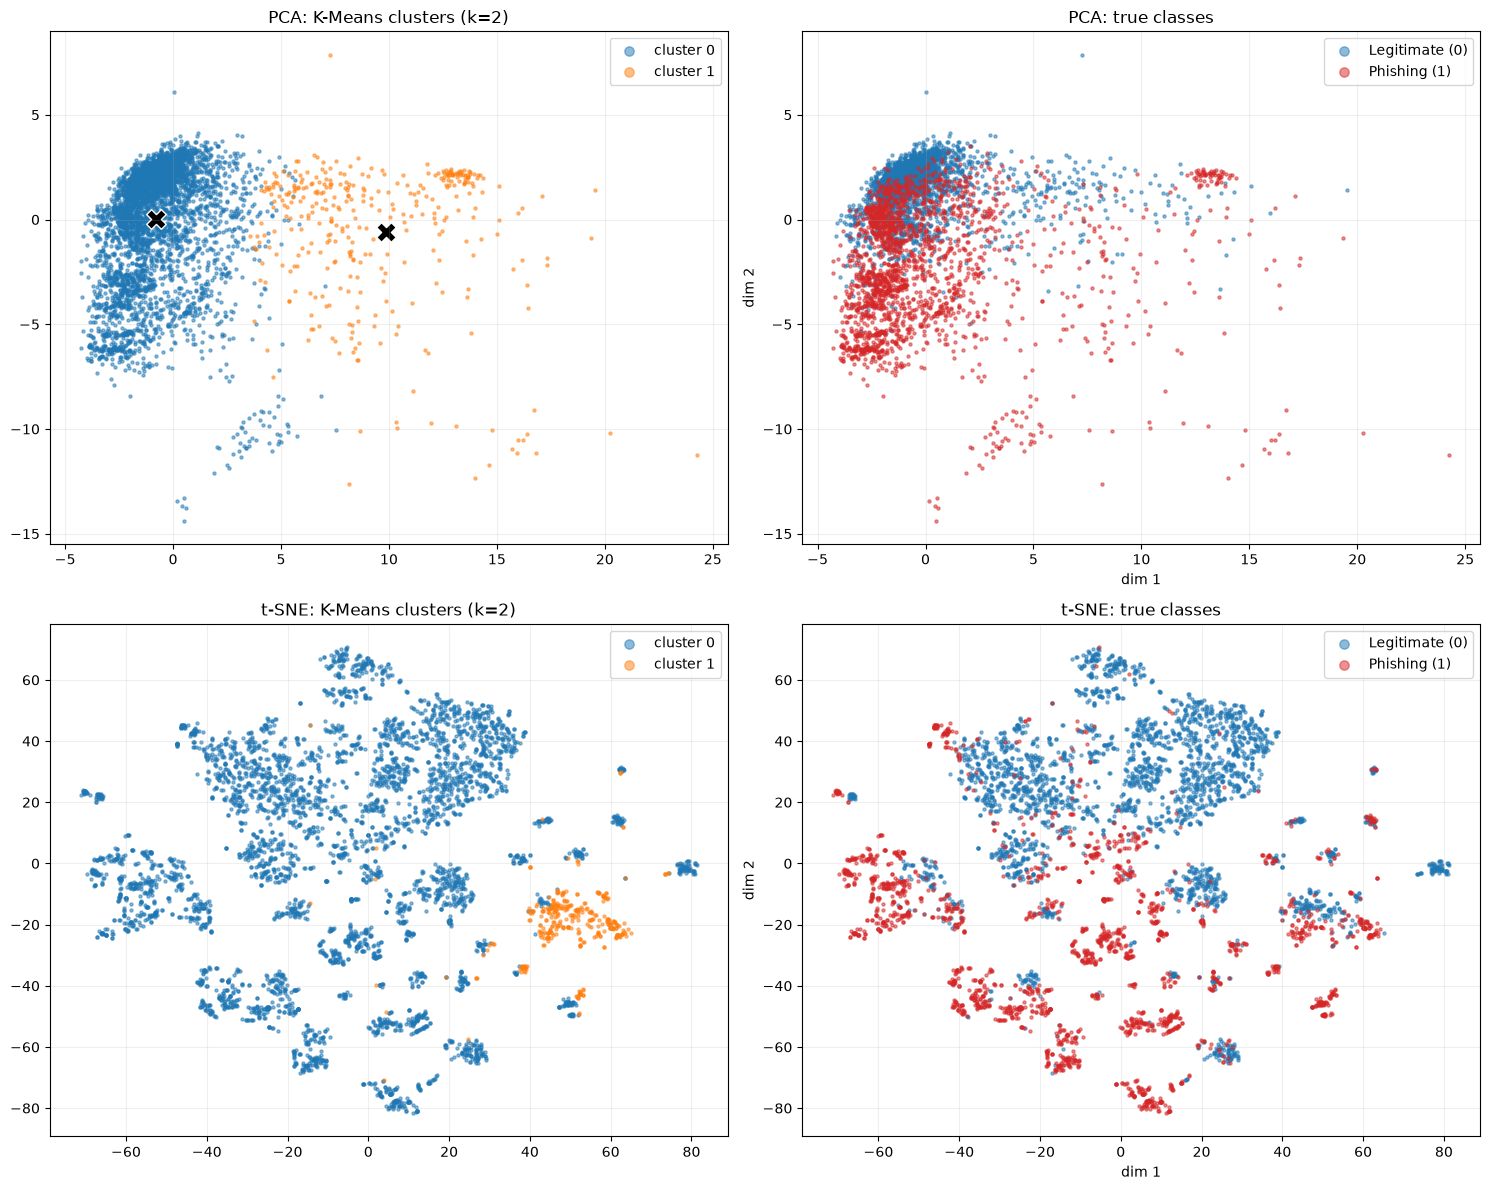

In [17]:
K_FINAL = k_sil
km = km_models[K_FINAL]
labels_c = km.labels_

VIS_N = 5_000
vis_idx = np.random.RandomState(RANDOM_STATE).choice(CLUSTER_N, VIS_N, replace=False)
Xv, lab_v, y_v = Xc[vis_idx], labels_c[vis_idx], y_true[vis_idx]

pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xc)
Z_pca = pca2.transform(Xv)
centers_2d = pca2.transform(km.cluster_centers_)

Xv_pre = PCA(n_components=min(50, Xv.shape[1]), random_state=RANDOM_STATE).fit_transform(Xv)
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
              random_state=RANDOM_STATE, n_jobs=-1).fit_transform(Xv_pre)

cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for row, (Z, name) in enumerate([(Z_pca, "PCA"), (Z_tsne, "t-SNE")]):
    for c in range(K_FINAL):
        m = lab_v == c
        axes[row, 0].scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, color=cmap(c), label=f"cluster {c}")
    axes[row, 0].set_title(f"{name}: K-Means clusters (k={K_FINAL})")
    axes[row, 0].legend(markerscale=3)
    scatter_classes(axes[row, 1], Z, y_v, f"{name}: true classes")
axes[0, 0].scatter(centers_2d[:, 0], centers_2d[:, 1], marker="X", s=200, c="black", edgecolor="white", label="centroids")
for ax in axes.ravel(): ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

### 2.4 Профіль кластерів
Щоб зрозуміти, **за якою ознакою** K-Means розділив дані, дивимося на середні значення ознак у кластерах (у вихідних одиницях). Показано ознаки, найбільше відмінні між центроїдами.

In [18]:
centers_z = pd.DataFrame(km.cluster_centers_, columns=X.columns)
spread = centers_z.std(axis=0).sort_values(ascending=False)
top_feats = spread.head(10).index.tolist()

profile = Xc_raw.assign(cluster=labels_c).groupby("cluster")[top_feats].mean()
profile["size"] = pd.Series(labels_c).value_counts().sort_index()
profile["phishing share"] = pd.Series(y_true).groupby(labels_c).mean()
display(profile.round(3))

print("Cluster-centroid spread (z-units), top features:")
print(spread.head(10).round(3).to_string())

,query_entropy,query_has_base64,query_length,num_question,num_params,query_value_length_avg,num_equals,num_ampersand,url_length,entropy_url,size,phishing share
cluster,,,,,,,,,,,,
0,0.0170,0.0010,0.0460,0.0080,0.0040,0.0090,0.0150,0.0030,44.4370,4.1010,46367,0.4040
1,4.0070,0.9310,75.4970,1.0430,2.0210,29.2080,2.2520,1.2110,144.5580,4.8620,3633,0.5800


Cluster-centroid spread (z-units), top features:
query_entropy            2.6160
query_has_base64         2.5980
query_length             2.5810
num_question             2.5580
num_params               2.4040
query_value_length_avg   2.4030
num_equals               2.3550
num_ampersand            1.6890
url_length               1.4290
entropy_url              1.3800


In [19]:
# Автоматичний підсумок порівняння кластерів із класами
m_f = cmp_metrics[K_FINAL]
m_2 = cmp_metrics[2]

def interp(ari):
    return ("практично не збігається" if ari < 0.1 else
            "збігається слабко" if ari < 0.3 else
            "збігається частково" if ari < 0.6 else "збігається добре")

print(f"Silhouette-оптимальне k = {k_sil}; Elbow радить k = {k_elbow}.")
for k, m in sorted(cmp_metrics.items()):
    print(f"k={k}: ARI={m['ARI']:.3f}, NMI={m['NMI']:.3f}, homogeneity={m['Homogeneity']:.3f}, "
          f"completeness={m['Completeness']:.3f}, purity={m['Purity']:.3f} -> розбиття {interp(m['ARI'])} з класами.")

Silhouette-оптимальне k = 2; Elbow радить k = 5.
k=2: ARI=0.016, NMI=0.009, homogeneity=0.006, completeness=0.016, purity=0.595 -> розбиття практично не збігається з класами.


### Висновки щодо кластеризації

- **Кількість кластерів.** Elbow зазвичай дає нечіткий «лікоть» (inertia падає плавно), тому надійніше спиратися на Silhouette та Davies-Bouldin; якщо оптимум за Silhouette не збігається з k = 2, це сигнал, що природна структура даних не зводиться до двох класів.
- **Кластер ≠ клас.** K-Means не знає про мітки: він групує за **геометричною близькістю** в просторі ознак (сферичні групи приблизно однакового розміру). Клас «Phishing» або «Legitimate» може складатися з кількох різних підтипів (наприклад, URL з наявними DNS/WHOIS-даними і без них), і тоді кілька кластерів відповідають одному класу, а чистота (purity) кластерів висока, але повнота (completeness) низька. Навпаки, якщо ознаки-«шум» мають велику дисперсію, кластери можуть відображати не клас, а технічну особливість (наприклад, довжину URL).
- **Збіг із реальними класами.** Оцінюється за ARI/NMI та таблицею спряженості: див. частку Phishing у кожному кластері. Кластер із часткою Phishing, близькою до 0 або 1, - «чистий»; частка біля загальної (~42 %) означає, що кластер не відрізняє класи.
- **Чому кластеризація гірша за класифікацію.** У Lab 1 Random Forest мав мітки й навчався відокремлювати саме класи; K-Means шукає найвиразнішу структуру в усіх ознаках без підказки, тому збіг із класами може бути лише частковим.
- **Обмеження.** Масштабування впливає на результат; K-Means чутливий до викидів (довгі хвости розподілів, див. EDA) та припускає опуклі кластери; 2D-проєкції (PCA, t-SNE) показують лише частину структури.

## 3) Обробка та класифікація текстових даних

### 3.1 Датасет
**SMS Spam Collection** (UCI ML Repository / Kaggle `uciml/sms-spam-collection-dataset`): ≈5 570 англомовних SMS, мітки `ham` (звичайне повідомлення) та `spam`. Класів лише два, тому скорочувати нічого не потрібно. За темою близько до фішингу з Lab 1: спам-SMS часто містять посилання, номери та заклики «виграти/зателефонувати».

Код нижче завантажує з UCI, а якщо це не вдалося - через `kagglehub`.

In [20]:
def load_sms():
    # 1) локальні файли (формат UCI: "label<TAB>text"; формат Kaggle: spam.csv з v1,v2)
    for p in ["SMSSpamCollection", os.path.join("data", "SMSSpamCollection")]:
        if os.path.exists(p):
            print("Using local file:", p)
            return pd.read_csv(p, sep="\t", header=None, names=["label", "text"], encoding="latin-1")
    for p in ["spam.csv", os.path.join("data", "spam.csv")]:
        if os.path.exists(p):
            print("Using local file:", p)
            d = pd.read_csv(p, encoding="latin-1")
            return d.rename(columns={"v1": "label", "v2": "text"})[["label", "text"]]
    # 2) UCI
    try:
        url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
        with urllib.request.urlopen(url, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        print("Downloaded from UCI")
        return pd.read_csv(z.open("SMSSpamCollection"), sep="\t", header=None,
                           names=["label", "text"], encoding="latin-1")
    except Exception as e:
        print("UCI download failed:", e)
    # 3) Kaggle
    import kagglehub
    path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")
    d = pd.read_csv(os.path.join(path, "spam.csv"), encoding="latin-1")
    print("Downloaded from Kaggle")
    return d.rename(columns={"v1": "label", "v2": "text"})[["label", "text"]]

sms = load_sms()
sms = sms.dropna().reset_index(drop=True)
print(sms.shape)
sms.head()

Downloaded from UCI
(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Class distribution:
       count  share
label              
ham     4825 0.8659
spam     747 0.1341

Exact duplicate messages: 403
After removing duplicates: (5169, 3) | spam share: 0.1263

Message length by class:
       n_chars               n_words             
          mean   median  max    mean  median  max
label                                            
ham    71.0000  53.0000  910 14.2000 11.0000  171
spam  138.1000 149.0000  224 23.7000 25.0000   35


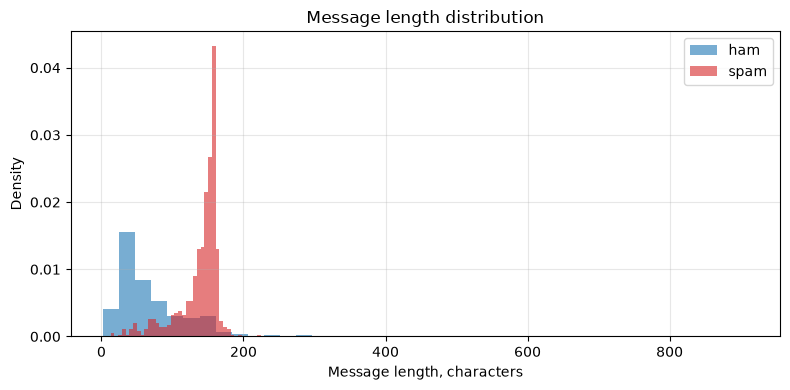

In [21]:
print("Class distribution:")
print(sms["label"].value_counts().to_frame("count").assign(share=lambda d: (d["count"] / d["count"].sum()).round(4)))

n_dup = sms.duplicated().sum()
print(f"\nExact duplicate messages: {n_dup}")
# Дублікати вилучаємо ДО розбиття, інакше однакове повідомлення опиниться і в train, і в test (витік).
sms = sms.drop_duplicates().reset_index(drop=True)
sms["y"] = (sms["label"] == "spam").astype(int)
print("After removing duplicates:", sms.shape, "| spam share:", sms["y"].mean().round(4))

sms["n_chars"] = sms["text"].str.len()
sms["n_words"] = sms["text"].str.split().str.len()
print("\nMessage length by class:")
print(sms.groupby("label")[["n_chars", "n_words"]].agg(["mean", "median", "max"]).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
for lab, color in [("ham", "tab:blue"), ("spam", "tab:red")]:
    ax.hist(sms.loc[sms["label"] == lab, "n_chars"], bins=40, alpha=0.6, color=color, label=lab, density=True)
ax.set_xlabel("Message length, characters"); ax.set_ylabel("Density"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Message length distribution")
plt.tight_layout(); plt.show()

### 3.2 Передобробка текстів
Кроки (усі «безстанові», тобто не навчаються на даних, тому не створюють витоку):

1. нижній регістр;
2. заміна посилань на токен `url`, а чисел - на токен `num` (конкретний номер телефону чи сума не узагальнюються, а сам факт їх наявності - сильна ознака спаму);
3. видалення розділових знаків та інших не-літер;
4. видалення стоп-слів (англійський список `sklearn` + кілька скорочень, типових для SMS: `u`, `ur`, `im`, `dont` тощо) та односимвольних токенів.

Лематизацію/стемінг не застосовуємо, щоб не залежати від завантаження корпусів NLTK; для цього датасету вони дають небагато.

In [22]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+)")
SMS_STOP = {"u", "ur", "im", "ive", "dont", "cant", "ill", "ll", "youre", "thats", "didnt",
            "doesnt", "wont", "isnt", "gt", "lt", "amp"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) | SMS_STOP

def clean_text(text):
    t = text.lower()
    t = URL_RE.sub(" url ", t)
    t = t.replace("'", "")                  # don't -> dont
    t = re.sub(r"\d+", " num ", t)
    t = re.sub(r"[^a-z\s]", " ", t)         # прибираємо пунктуацію, символи, емодзі
    tokens = [w for w in t.split() if len(w) > 1 and w not in STOP_WORDS]
    return " ".join(tokens)

sms["clean"] = sms["text"].apply(clean_text)

for i in sms.sample(4, random_state=RANDOM_STATE).index:
    print(f"[{sms.loc[i, 'label']}]")
    print("  raw  :", sms.loc[i, "text"])
    print("  clean:", sms.loc[i, "clean"], "\n")

print("Empty after cleaning:", (sms["clean"].str.len() == 0).sum())
print("Mean words before / after:", sms["n_words"].mean().round(1), "/", sms["clean"].str.split().str.len().mean().round(1))

[ham]
  raw  : K, makes sense, btw carlos is being difficult so you guys are gonna smoke while I go pick up the second batch and get gas
  clean: makes sense btw carlos difficult guys gonna smoke pick second batch gas 

[spam]
  raw  : URGENT! Your mobile No *********** WON a Â£2,000 Bonus Caller Prize on 02/06/03! This is the 2nd attempt to reach YOU! Call 09066362220 ASAP! BOX97N7QP, 150ppm
  clean: urgent mobile won num num bonus caller prize num num num num nd attempt reach num asap box num num qp num ppm 

[ham]
  raw  : If you still havent collected the dough pls let me know so i can go to the place i sent it to get the control number
  clean: havent collected dough pls let know place sent control number 

[ham]
  raw  : Wat time do u wan 2 meet me later?
  clean: wat time wan num meet later 

Empty after cleaning: 21
Mean words before / after: 15.4 / 8.1


### 3.3 Розбиття на train / test
Розбиваємо **до** побудови словників WordCloud та TF-IDF: частоти слів і IDF рахуємо лише за training-частиною, щоб test лишився «невидимим».

In [23]:
train_df, test_df = train_test_split(sms, test_size=0.20, random_state=RANDOM_STATE, stratify=sms["y"])
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Spam share train / test:", train_df["y"].mean().round(4), "/", test_df["y"].mean().round(4))

Train: (4135, 6) | Test: (1034, 6)
Spam share train / test: 0.1262 / 0.1267


### 3.4 WordCloud: найхарактерніші слова та словосполучення
Розмір слова пропорційний його частоті у повідомленнях цього класу (training). Окремо будуємо хмари для **біграм** (пар слів), бо вони передають контекст («call now», «free entry»). Бібліотека `wordcloud` встановлюється автоматично, якщо її немає.

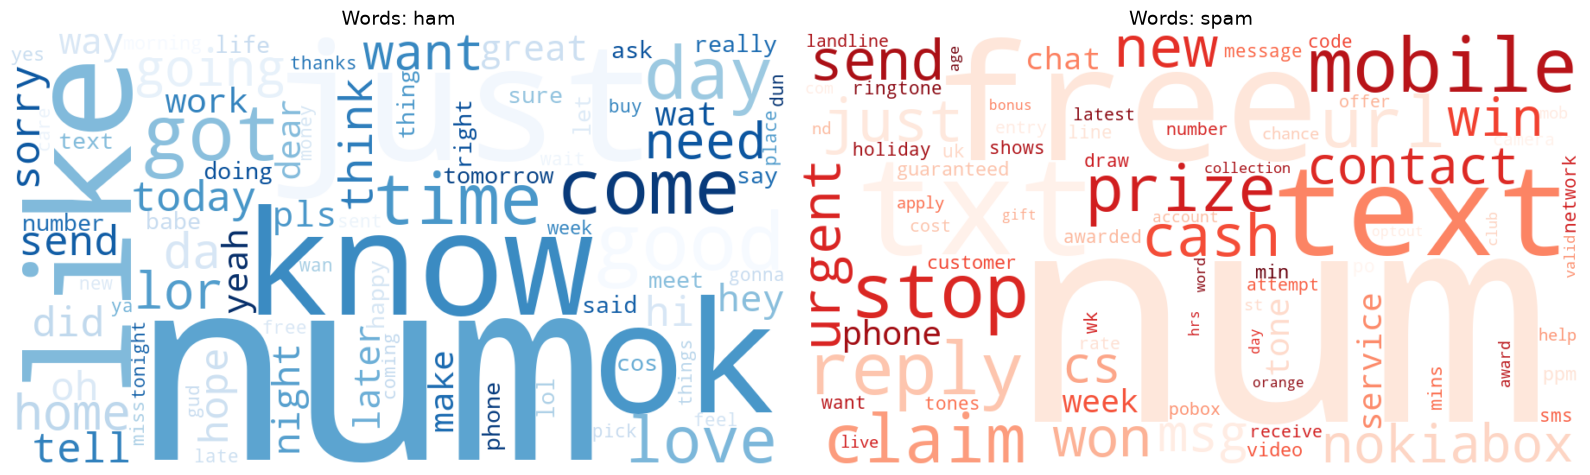

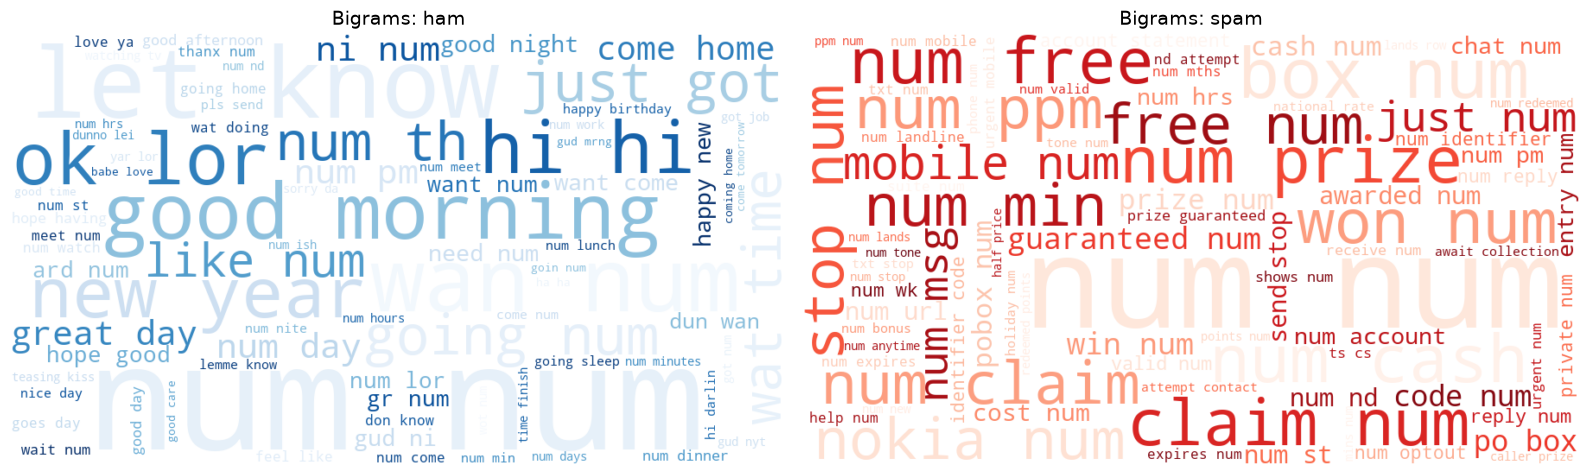

In [24]:
try:
    from wordcloud import WordCloud
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "wordcloud"])
    from wordcloud import WordCloud

def class_counts(texts, ngram_range):
    cv = CountVectorizer(ngram_range=ngram_range)
    M = cv.fit_transform(texts)
    return dict(zip(cv.get_feature_names_out(), np.asarray(M.sum(axis=0)).ravel()))

freq = {}
for cls, name in [(0, "ham"), (1, "spam")]:
    texts = train_df.loc[train_df["y"] == cls, "clean"]
    freq[(name, 1)] = class_counts(texts, (1, 1))
    freq[(name, 2)] = class_counts(texts, (2, 2))

def draw_clouds(n, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, name, cmap_name in zip(axes, ["ham", "spam"], ["Blues", "Reds"]):
        wc = WordCloud(width=900, height=500, background_color="white", colormap=cmap_name,
                       max_words=80, random_state=RANDOM_STATE).generate_from_frequencies(freq[(name, n)])
        ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"{title}: {name}", fontsize=14)
    plt.tight_layout(); plt.show()

draw_clouds(1, "Words")
draw_clouds(2, "Bigrams")

Частотна хмара показує і слова, спільні для обох класів. Щоб побачити **саме характерні** слова, порахуємо для кожного слова згладжене **log-odds ratio** між класами: `log P(w|spam) − log P(w|ham)`. Додатні значення - слово типове для спаму, від'ємні - для ham (враховуємо слова, що трапляються щонайменше 5 разів).

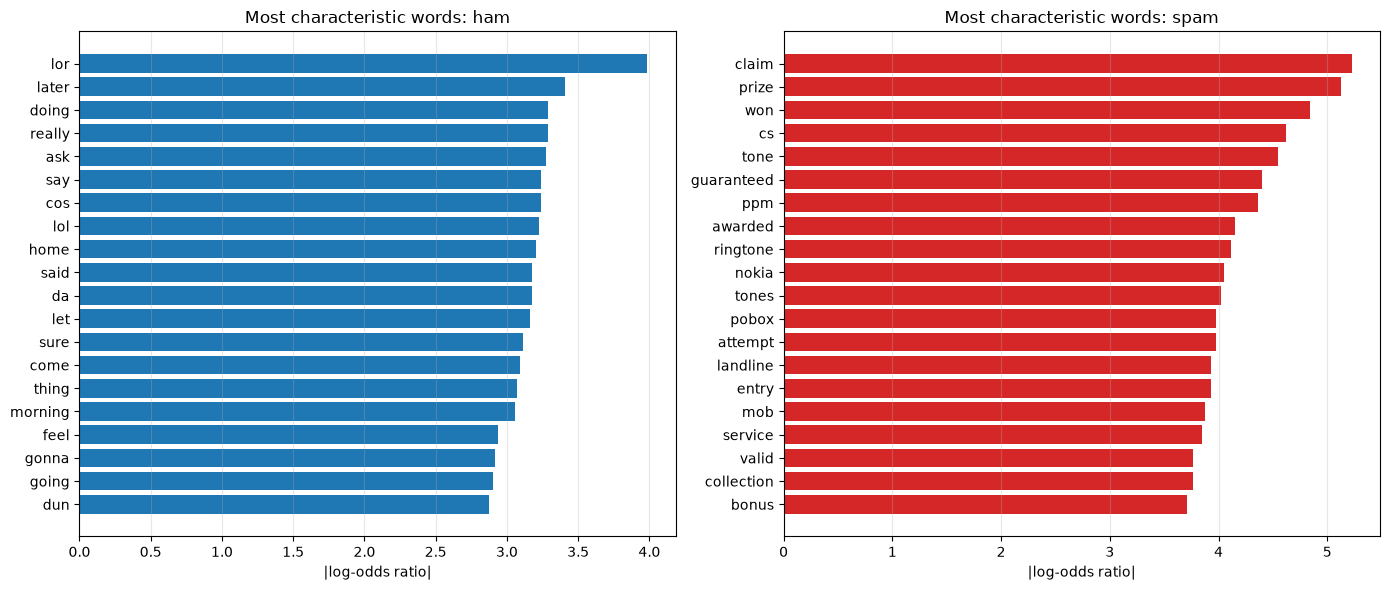

In [25]:
uni_spam, uni_ham = freq[("spam", 1)], freq[("ham", 1)]
vocab = [w for w in set(uni_spam) | set(uni_ham) if uni_spam.get(w, 0) + uni_ham.get(w, 0) >= 5]
n_spam, n_ham, V = sum(uni_spam.values()), sum(uni_ham.values()), len(vocab)
log_odds = pd.Series({w: np.log((uni_spam.get(w, 0) + 1) / (n_spam + V))
                         - np.log((uni_ham.get(w, 0) + 1) / (n_ham + V)) for w in vocab}).sort_values()

top_spam = log_odds.tail(20)[::-1]
top_ham = log_odds.head(20)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top_ham.index[::-1], -top_ham.values[::-1], color="tab:blue"); axes[0].set_title("Most characteristic words: ham")
axes[1].barh(top_spam.index[::-1], top_spam.values[::-1], color="tab:red"); axes[1].set_title("Most characteristic words: spam")
for ax in axes: ax.set_xlabel("|log-odds ratio|"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

**Як інтерпретувати хмари та діаграму**:

- **spam:** великі слова мають бути «рекламно-закличними»: `free`, `call`, `claim`, `prize`, `win`, `text`, `txt`, `mobile`, `reply`, `stop`, `urgent` та токени `num` (номери телефонів, суми, короткі коди) й `url`. Біграми на кшталт `call num`, `free entry`, `prize guaranteed`. Це типові ознаки масової розсилки: заклик до дії + грошова вигода + номер для відповіді.
- **ham:** переважають розмовні слова (`ok`, `like`, `going`, `home`, `got`, `know`, `time`, `love`), тобто особисте листування, без закликів і чисел.
- Слова на кшталт `num` підтверджують, що наша заміна чисел залишила корисний сигнал. Частотна хмара без підсумку log-odds показує і загальновживані слова, а діаграма log-odds - саме ті, що відрізняють класи.
- Це «слова, що відрізняють класи» у цій вибірці; вони допомагають зрозуміти, що саме вивчить модель на наступному кроці.

### 3.5 Векторизація: TF-IDF
`TfidfVectorizer` перетворює кожне повідомлення на розріджений вектор: вага слова = частота в повідомленні × обернена частота в документах (рідкісні, але характерні слова важать більше). Параметри: уніграми та біграми, `min_df=2` (слова, що зустрілися хоча б у двох повідомленнях), `sublinear_tf=True` (логарифмування частоти). Словник і IDF навчаються лише на training.

In [26]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_tr = tfidf.fit_transform(train_df["clean"])
X_te = tfidf.transform(test_df["clean"])
y_tr, y_te = train_df["y"].values, test_df["y"].values

density = X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1])
print("TF-IDF train matrix:", X_tr.shape, f"| density: {density:.4%}")
print("Test matrix        :", X_te.shape)

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print("\nMost common terms (lowest IDF):", idf.head(8).index.tolist())
print("Rarest terms (highest IDF):    ", idf.tail(5).index.tolist())

TF-IDF train matrix: (4135, 5473) | density: 0.1582%
Test matrix        : (1034, 5473)

Most common terms (lowest IDF): ['num', 'num num', 'just', 'ok', 'know', 'good', 'like', 'got']
Rarest terms (highest IDF):     ['acl', 'accounts', 'account details', 'account bank', 'accident claim']


### 3.6 Навчання та оцінка класифікаторів
Порівнюємо три класичні моделі для тексту + «тривіальний» baseline:

- **Dummy** (завжди передбачає більший клас) - показує, чому accuracy тут не годиться (класи незбалансовані: спаму ≈ 13 %);
- **Multinomial Naive Bayes** - класика для частот слів;
- **Logistic Regression** і **Linear SVM** - лінійні моделі, дуже ефективні на розріджених TF-IDF-векторах. Для них `class_weight="balanced"` підсилює вагу меншого класу.

Гіперпараметри (`alpha` для NB, `C` для LR та SVM) підбираємо за 5-fold CV **на training** (метрика F1 для спаму) у `Pipeline`, щоб TF-IDF навчався тільки на train-частині кожного фолда. Test використовуємо лише для фінальної оцінки.

In [27]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ("clf", clf)])

searches = {
    "Naive Bayes": GridSearchCV(make_pipe(MultinomialNB()),
                                {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 1.0]}, cv=cv5, scoring="f1", n_jobs=-1),
    "Logistic Regression": GridSearchCV(make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")),
                                        {"clf__C": [0.1, 1, 10, 100]}, cv=cv5, scoring="f1", n_jobs=-1),
    "Linear SVM": GridSearchCV(make_pipe(LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)),
                               {"clf__C": [0.01, 0.1, 1, 10]}, cv=cv5, scoring="f1", n_jobs=-1),
}
for name, gs in searches.items():
    t0 = time.time(); gs.fit(train_df["clean"], y_tr)
    print(f"{name:20s} best params: {gs.best_params_}  CV F1 = {gs.best_score_:.4f}  ({time.time() - t0:.1f} s)")

Naive Bayes          best params: {'clf__alpha': 0.1}  CV F1 = 0.9287  (11.5 s)
Logistic Regression  best params: {'clf__C': 100}  CV F1 = 0.9380  (2.1 s)
Linear SVM           best params: {'clf__C': 1}  CV F1 = 0.9328  (1.6 s)


In [28]:
def text_metrics(name, y_true, y_pred, score):
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision (spam)": precision_score(y_true, y_pred),
            "Recall (spam)": recall_score(y_true, y_pred),
            "F1 (spam)": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, score)}

rows, fitted = [], {}

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
rows.append(text_metrics("Dummy (always ham)", y_te, dummy.predict(X_te), np.zeros(len(y_te))))

for name, gs in searches.items():
    model = gs.best_estimator_                       # Pipeline, уже навчений на всьому train
    X_raw = test_df["clean"]
    y_pred = model.predict(X_raw)
    score = model.predict_proba(X_raw)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_raw)
    rows.append(text_metrics(name, y_te, y_pred, score))
    fitted[name] = (model, y_pred)

text_results = pd.DataFrame(rows).set_index("Model")
display(text_results.round(4))

,Accuracy,Precision (spam),Recall (spam),F1 (spam),ROC-AUC
Model,,,,,
Dummy (always ham),0.8733,0.0000,0.0000,0.0000,0.5000
Naive Bayes,0.9855,0.9603,0.9237,0.9416,0.9926
Logistic Regression,0.9816,0.9516,0.9008,0.9255,0.9961
Linear SVM,0.9826,0.9520,0.9084,0.9297,0.9955


Best model by F1 (spam): Naive Bayes

              precision    recall  f1-score   support

         ham     0.9890    0.9945    0.9917       903
        spam     0.9603    0.9237    0.9416       131

    accuracy                         0.9855      1034
   macro avg     0.9747    0.9591    0.9667      1034
weighted avg     0.9854    0.9855    0.9854      1034



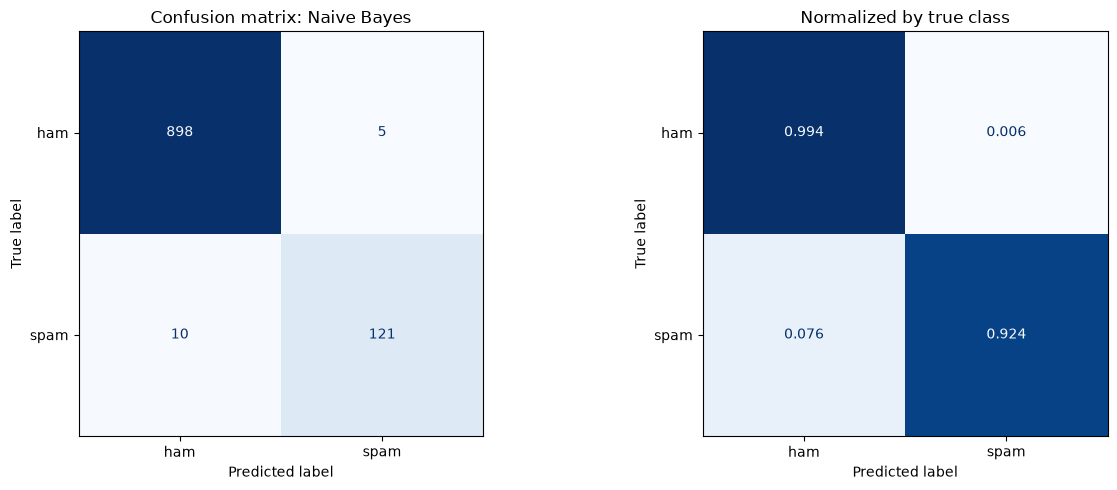

In [29]:
best_name = text_results.drop(index="Dummy (always ham)")["F1 (spam)"].idxmax()
best_model, best_pred = fitted[best_name]
print(f"Best model by F1 (spam): {best_name}\n")
print(classification_report(y_te, best_pred, target_names=["ham", "spam"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_te, best_pred), display_labels=["ham", "spam"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix: {best_name}")
ConfusionMatrixDisplay.from_predictions(y_te, best_pred, normalize="true", display_labels=["ham", "spam"],
                                        ax=axes[1], cmap="Blues", colorbar=False, values_format=".3f")
axes[1].set_title("Normalized by true class")
plt.tight_layout(); plt.show()

### 3.7 Що вивчила модель і де вона помиляється
Для лінійних моделей коефіцієнти показують внесок слів; а розбір помилок допомагає зрозуміти обмеження моделі.

In [30]:
lin_name = next((n for n in ["Logistic Regression", "Linear SVM"] if n in fitted), None)
lin_pipe = fitted[lin_name][0]
coef = pd.Series(lin_pipe.named_steps["clf"].coef_.ravel(), index=lin_pipe.named_steps["tfidf"].get_feature_names_out())
print(f"Top terms pushing towards SPAM ({lin_name}):")
print(coef.sort_values(ascending=False).head(15).round(3).to_string())
print("\nTop terms pushing towards HAM:")
print(coef.sort_values().head(15).round(3).to_string())

errors = test_df.assign(pred=best_pred)
fn = errors[(errors["y"] == 1) & (errors["pred"] == 0)]
fp = errors[(errors["y"] == 0) & (errors["pred"] == 1)]
print(f"\nBest model ({best_name}): false negatives (spam missed) = {len(fn)}, false positives (ham flagged) = {len(fp)}")
for title, part in [("MISSED SPAM", fn), ("HAM FLAGGED AS SPAM", fp)]:
    print(f"\n--- {title} (up to 4 examples) ---")
    for t in part["text"].head(4):
        print(" *", t[:200])

Top terms pushing towards SPAM (Logistic Regression):
url        15.6030
txt        12.2810
mobile     10.8110
num num    10.4180
service     9.0600
reply       8.8360
arsenal     8.6460
uk          8.6070
won         8.3670
claim       8.3480
video       8.3400
brought     7.5940
rgds        7.4410
ringtone    7.4270
sexy        7.2860

Top terms pushing towards HAM:
make            -5.8360
home            -5.7160
ok              -5.2820
face            -5.1370
later           -4.5010
fullonsms       -4.0450
fullonsms com   -4.0450
hey             -4.0030
got             -3.9310
test            -3.8170
great place     -3.7590
mail            -3.7480
liked           -3.7440
list            -3.6830
way             -3.5220

Best model (Naive Bayes): false negatives (spam missed) = 10, false positives (ham flagged) = 5

--- MISSED SPAM (up to 4 examples) ---
 * ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE 

In [ ]:
d = text_results.drop(index="Dummy (always ham)")
best = d.loc[best_name]
dm = text_results.loc["Dummy (always ham)"]
print("ПІДСУМОК (класифікація текстів)")
print(f"- Тривіальний baseline дає accuracy {dm['Accuracy']:.3f}, але recall для спаму = 0: на цих даних accuracy не інформативна.")
print(f"- Найкраща модель: {best_name}: accuracy {best['Accuracy']:.4f}, precision(spam) {best['Precision (spam)']:.4f}, "
      f"recall(spam) {best['Recall (spam)']:.4f}, F1(spam) {best['F1 (spam)']:.4f}, ROC-AUC {best['ROC-AUC']:.4f}.")
print(f"- Помилки на test: пропущено спаму {len(fn)}, хибних тривог {len(fp)} із {len(test_df)} повідомлень.")
print("- Різниця між моделями за F1:", (d['F1 (spam)'].max() - d['F1 (spam)'].min()).round(4))

ПІДСУМОК (класифікація текстів)
- Тривіальний baseline дає accuracy 0.873, але recall для спаму = 0: на цих даних accuracy не інформативна.
- Найкраща модель: Naive Bayes: accuracy 0.9855, precision(spam) 0.9603, recall(spam) 0.9237, F1(spam) 0.9416, ROC-AUC 0.9926.
- Помилки на test: пропущено спаму 10, хибних тривог 5 із 1034 повідомлень.
- Різниця між моделями за F1: 0.0161


### Висновки щодо класифікації текстів
- **Метрики.** Класи незбалансовані (спаму ≈ 13 %), тому головною метрикою обрано **F1 для класу spam** разом із precision/recall: baseline «усе - ham» має високу accuracy, але нульовий recall. Precision показує, яка частка повідомлень, позначених як спам, справді спам (ціна хибної тривоги - втрачений легітимний лист), recall - яку частку спаму знайдено (ціна пропуску - спам у вхідних). ROC-AUC не залежить від порогу.
- **Порівняння моделей.** Лінійні моделі та Naive Bayes на TF-IDF зазвичай дають дуже близькі результати - тексти добре розділяються за наявністю окремих слів (див. WordCloud: `free`, `call`, `prize`, `num`, `url`), тож складніша модель не потрібна. Різниця між моделями порівнянна з розкидом CV, тож її не варто надто перебільшувати.
- **Помилки.** Моделі пропускають спам, який виглядає як звичайна переписка (без посилань і чисел), і помилково позначають розмовні повідомлення, що містять «спамні» слова або числа (див. приклади вище).
- **Обмеження.** Невеликий датасет (≈5 тис. повідомлень, англійською, стару добу SMS), тому результати не переносяться на сучасні фішингові повідомлення без перенавчання; TF-IDF не враховує порядок слів та семантику (її дають embedding-моделі).

## Загальні висновки
1. **PCA** стискає ознаки Lab 1 до значно меншої кількості компонент при збереженні 95 % дисперсії; вплив на якість і час оцінено в п. 1.3. Для дерев/лісу PCA не потрібен для якості, але зменшує розмірність даних; ціною є втрата інтерпретовності.
2. **t-SNE** допомагає візуально оцінити, наскільки класи розділяються в просторі ознак, і виявити внутрішню структуру класів, але придатний лише для візуалізації.
3. **K-Means** знаходить структуру без міток; її збіг із реальними класами оцінюється ARI/NMI та таблицею спряженості - кластер і клас не обов'язково збігаються.
4. **Тексти:** після очищення, TF-IDF-векторизації та простих лінійних моделей SMS-спам класифікується з високими precision/recall; WordCloud та коефіцієнти моделі пояснюють, за якими словами.